In [1]:
import sys; from pathlib import Path;
src_dir = next(parent / 'src' for parent in Path().absolute().parents if (parent / 'src').is_dir())
sys.path.extend([str(src_dir), str(src_dir / 'pipelines')])
main_dir = Path(src_dir.parents[0])
from imports import * ; current_dir = Path().resolve()  ; parent_dir = current_dir.parents[1]
import tifffile as tiff
from matplotlib.widgets import Button
from matplotlib.patches import Rectangle


In [2]:
folder_path = Path('/Volumes/Luis_DRIVE/UTag_paper_data/Translocation')
if not folder_path.is_dir():
    raise FileNotFoundError(f'Required translocation source is unavailable: {folder_path}')

In [3]:
def get_mean_images(tag, time, folder_path, pixel_filter=None):
    """
    Returns a list of full file paths that match the specified tag and time criteria.
    
    Parameters:
    -----------
    tag : str
        The tag type. Must be one of: 'SunTag', 'Alfatag', 'UTag_CF', 'UTag'
    time : str or None
        The time period. Must be one of: '24hr', '48hr', or None.
        If None, all time points are selected and sorted (24hr first, then 48hr).
    folder_path : str or Path, optional
        Path to the folder containing the files. If None, uses the global folder_path.
    pixel_filter : str or None, optional
        Filter images by pixel size. Options:
        - 'high_res': Only include images with pixel_xy_um ~0.1 (≤0.15)
        - 'low_res': Only include images with pixel_xy_um ~0.2 (>0.15)
        - None: Include all images regardless of pixel size
        
    Returns:
    --------
    tuple
        (matching_file_names, list_mean_images_all_files, list_names_all_files, 
         list_pixels_size, tag, time)
        
    Examples:
    ---------
    # Get specific time point with all pixel sizes
    results = get_mean_images(tag='UTag_CF', time='24hr', folder_path=folder_path)
    
    # Get only low resolution images (~0.2 pixel size)
    results = get_mean_images(tag='UTag_CF', time=None, folder_path=folder_path, pixel_filter='low_res')
    
    # Get only high resolution images (~0.1 pixel size)
    results = get_mean_images(tag='UTag_CF', time=None, folder_path=folder_path, pixel_filter='high_res')
    """
    
    # Tag to plasmid ID mapping
    tag_to_plasmid = {
        'SunTag': 'pNZ317',
        'Alfatag': 'pJY016', 
        'UTag_CF': 'pNZ377',
        'UTag': 'pNZ335'
    }
    
    if tag not in tag_to_plasmid:
        raise ValueError(f"Invalid tag '{tag}'. Must be one of: {list(tag_to_plasmid.keys())}")
    
    if time is not None and time not in ['24hr', '48hr']:
        raise ValueError(f"Invalid time '{time}'. Must be '24hr', '48hr', or None")
    
    if pixel_filter is not None and pixel_filter not in ['high_res', 'low_res']:
        raise ValueError(f"Invalid pixel_filter '{pixel_filter}'. Must be 'high_res', 'low_res', or None")
    
    plasmid_id = tag_to_plasmid[tag]
    lif_files = list(folder_path.glob('*.lif'))
    
    matching_files_24hr = []
    matching_files_48hr = []
    
    for file_path in lif_files:
        filename = file_path.name
        if plasmid_id in filename:
            if '24hr' in filename or '24 hrs' in filename:
                matching_files_24hr.append(file_path)
            elif '48hr' in filename or '48 hrs' in filename:
                matching_files_48hr.append(file_path)
    
    matching_files_24hr.sort(key=lambda x: x.name)
    matching_files_48hr.sort(key=lambda x: x.name)
    
    if time == '24hr':
        matching_files = matching_files_24hr
    elif time == '48hr':
        matching_files = matching_files_48hr
    elif time is None:
        # Combine with 24hr first, then 48hr
        matching_files = matching_files_24hr + matching_files_48hr
    
    list_mean_images_all_files = []
    list_names_all_files = []
    list_pixels_size = []
    matching_file_names = []
    
    for file_path in matching_files:
        list_images, list_names, pixel_xy_um, _, _, _,_, _,_,_,_  = mi.ReadLif(file_path,show_metadata=False,save_tif=False,save_png=False,format='TZYXC').read()
        
        # Apply pixel size filter
        skip_file = False
        if pixel_filter == 'high_res' and pixel_xy_um > 0.15:
            skip_file = True
            print(f"Skipping {file_path.name}: pixel size {pixel_xy_um:.3f} > 0.15 (high_res filter)")
        elif pixel_filter == 'low_res' and pixel_xy_um <= 0.15:
            skip_file = True
            print(f"Skipping {file_path.name}: pixel size {pixel_xy_um:.3f} <= 0.15 (low_res filter)")
        if skip_file:
            continue
        list_mean_per_file = []
        list_names_per_file = []
        for i, image in enumerate(list_images):
            img_ch0 = image[..., 0]
            mean_int = np.mean(img_ch0, axis=(0, 1))
            #mean_int = np.clip(mean_int, 0, np.percentile(mean_int, 99.5))
            list_mean_per_file.append(mean_int)
            list_names_per_file.append(list_names[i])
        list_mean_images_all_files.append(list_mean_per_file)
        list_names_all_files.append(list_names_per_file)
        list_pixels_size.append(pixel_xy_um)
        matching_file_names.append(file_path.name)
        print(f"Included {file_path.name}: pixel size {pixel_xy_um:.3f}")
    return matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time


In [4]:
def plot_images(list_images, list_image_names_per_file=None, file_name=None, tag='', maximum_images_to_plot=None,microns_per_pixel=None,folder_path=None ):
    if maximum_images_to_plot is not None and maximum_images_to_plot > 0:
        list_images = list_images[:maximum_images_to_plot]
        if list_image_names_per_file is not None:
            list_image_names_per_file = list_image_names_per_file[:maximum_images_to_plot]
        print(f"Displaying {len(list_images)} out of total images (limited by maximum_images_to_plot={maximum_images_to_plot})")
    
    n_images = len(list_images)
    
    if n_images == 0:
        print("No images to plot.")
        return
    n_cols = 10
    n_rows = int(np.ceil(n_images / n_cols))
    # Adjust figure height based on number of rows to prevent overlap
    if n_rows == 1:
        fig_height = n_rows * 3 + 1  # Add extra space for single row
        suptitle_y = 0.95  # Lower position for single row
    else:
        fig_height = n_rows * 3
        suptitle_y = 0.98  # Higher position for multiple rows
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, fig_height))
    # Handle single subplot case (when n_rows=1 and n_cols=1)
    if n_rows == 1 and n_cols == 1:
        axes = [axes]
    elif n_rows == 1 or n_cols == 1:
        axes = axes.flatten()
    else:
        axes = axes.flatten()
    font_props = {'size': 8, }
    for i, (image, ax) in enumerate(zip(list_images, axes)):
        vmin = np.percentile(image, 1)
        vmax = np.percentile(image, 99.9)
        ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax)
        # Set the title with smaller font for single row to reduce overlap
        title_fontsize = 10 if n_rows == 1 else 12
        if list_image_names_per_file is not None:
            ax.set_title(list_image_names_per_file[i], fontsize=title_fontsize)
        ax.set_xticks([])
        ax.set_yticks([])
        if microns_per_pixel is not None:
            scalebar = ScaleBar(dx=microns_per_pixel, units='um', length_fraction=0.25,
                                location='lower right', box_color='k', color='w',
                                font_properties=font_props, label='')
            ax.add_artist(scalebar)
    for j in range(i + 1, n_rows * n_cols):
        axes[j].axis('off')
    if file_name is None:
        plot_title = ""
    else:
        plot_title = Path(file_name).stem
    if tag == 'UTag_CF':
        tag = "UTag($\Delta$Cys)"
    plt.suptitle(tag + " " + plot_title, fontsize=30, y=suptitle_y)
    if n_rows == 1:
        plt.tight_layout(rect=[0, 0, 1, 0.92])  # Leave space at top for suptitle
    else:
        plt.tight_layout(rect=[0, 0, 1, 0.96])  # Less space needed for multiple rows
    save_png_path = folder_path.joinpath(tag).with_suffix('.png')
    plt.savefig(save_png_path, dpi=300)
    print(f"Saved figure as {save_png_path}")
    plt.show()


In [5]:
def plot_images_line(
    list_images,
    list_image_names_per_file=None,
    microns_per_pixel=None,            # float in µm/pixel (XY). If provided, written as calibration.
    list_selected_indexes=None,
    save_tif_dir=None,                 # directory path; if provided, writes ONE .tif per selected image
    filename_prefix="",                # optional prefix for filenames
    overwrite=False                    # if False, raise if target file exists
):
    """
    Plot a single row from a list of 2D images and (optionally) save ONE ImageJ .tif per image.

    - Input: list of 2D arrays (Y, X).
    - Selection: list_selected_indexes preserves order (supports negatives).
    - Export: if save_tif_dir is provided, writes one ImageJ .tif per image.
      * imagej=True, ome=False
      * metadata={'unit': 'um', 'axes': 'YX'} (no OME keys)
      * TIFF 'resolution' = pixels per centimeter (px/cm), resolutionunit='CENTIMETER'
    """
    # ---------- helpers ----------
    def _ensure_2d(arr, name_for_error="image"):
        arr = np.asarray(arr)
        if arr.ndim != 2:
            raise ValueError(f"{name_for_error} must be 2D (Y,X). Got shape {arr.shape}.")
        return arr

    def _sanitize_filename(s):
        base = str(s).strip().replace(' ', '_')
        return re.sub(r'[^A-Za-z0-9_\-]+', '', base) or "image"

    def _compute_resolution_tags(pixel_um):
        """
        TIFF stores XResolution/YResolution as 'pixels per unit'.
        We use unit = CENTIMETER: px/cm = 10000 / (µm/pixel).
        """
        if pixel_um is None:
            return (None, None)
        pixel_um = float(pixel_um)
        if pixel_um <= 0:
            raise ValueError("microns_per_pixel must be > 0.")
        px_per_cm = 10000.0 / pixel_um
        return ((px_per_cm, px_per_cm), "CENTIMETER")

    def _to_imagej_compatible_dtype(arr):
        """
        Convert array to an ImageJ-compatible dtype without changing dynamic range
        (no normalization). Returns a contiguous array with dtype in {uint8, uint16, int16, float32}.
        """
        a = np.asarray(arr)
        # Allowed ImageJ dtypes per tifffile: 'B' (uint8), 'H' (uint16), 'h' (int16), 'f' (float32)
        if a.dtype == np.uint8 or a.dtype == np.uint16 or a.dtype == np.int16 or a.dtype == np.float32:
            return np.ascontiguousarray(a)
        if a.dtype == np.bool_:
            # map False/True -> 0/255 (uint8)
            return np.ascontiguousarray(a.astype(np.uint8) * 255)
        if np.issubdtype(a.dtype, np.floating):
            # float64/float16 -> float32 (no scaling)
            return np.ascontiguousarray(a.astype(np.float32))
        # other integer types (int8, int32, int64, uint32, uint64) -> float32 to avoid overflow
        return np.ascontiguousarray(a.astype(np.float32))

    # ---------- selection ----------
    total_images = len(list_images)
    if total_images == 0:
        print("No images to plot.")
        return []

    if list_selected_indexes is None:
        selected_indices = list(range(total_images))
    else:
        if isinstance(list_selected_indexes, (int, np.integer)):
            selected_raw = [int(list_selected_indexes)]
        else:
            selected_raw = [int(i) for i in list_selected_indexes]

        selected_indices, invalid = [], []
        for idx in selected_raw:
            if -total_images <= idx < total_images:
                if idx < 0:
                    idx = total_images + idx
                selected_indices.append(idx)
            else:
                invalid.append(idx)
        if invalid:
            print(f"Ignoring out-of-range indices: {invalid}")
        if not selected_indices:
            print("No valid selected indexes; nothing to plot.")
            return []

    selected_images = [_ensure_2d(list_images[i], name_for_error=f"image idx {i}") for i in selected_indices]

    if list_image_names_per_file is not None:
        names_len = len(list_image_names_per_file)
        selected_names = [
            list_image_names_per_file[i] if 0 <= i < names_len else None
            for i in selected_indices
        ]
    else:
        selected_names = [None] * len(selected_indices)

    # ---------- plot as a single row ----------
    n_cols = len(selected_images)
    fig, axes = plt.subplots(1, n_cols, figsize=(n_cols * 3, 3))
    axes = np.atleast_1d(axes).ravel()

    for i, (img, ax) in enumerate(zip(selected_images, axes)):
        arr = np.asarray(img)
        vmin = np.percentile(arr, 1)
        vmax = np.percentile(arr, 99.9)
        if vmin == vmax:
            ax.imshow(arr, cmap='gray')
        else:
            ax.imshow(arr, cmap='gray', vmin=vmin, vmax=vmax)

        if selected_names[i] is not None:
            ax.set_title(str(selected_names[i]), fontsize=10)

        ax.set_xticks([])
        ax.set_yticks([])

        if microns_per_pixel is not None:
            ax.add_artist(ScaleBar(
                dx=microns_per_pixel, units='um', length_fraction=0.25,
                location='lower right', box_color='k', color='w',
                font_properties={'size': 8}, label=''
            ))

    plt.tight_layout()
    plt.show()

    # ---------- save ONE ImageJ TIFF per image ----------
    saved_paths = []
    if save_tif_dir is None:
        return saved_paths  # plotting only

    out_dir = Path(save_tif_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    resolution, resolutionunit = _compute_resolution_tags(microns_per_pixel)

    # ImageJ-only metadata (no OME fields)
    base_metadata = {'axes': 'YX'}
    if microns_per_pixel is not None:
        base_metadata['unit'] = 'um'

    for i, (idx, img, name) in enumerate(zip(selected_indices, selected_images, selected_names)):
        # choose filename
        if name is not None:
            stem = _sanitize_filename(Path(str(name)).stem)
        else:
            stem = f"img_{idx:04d}"
        if filename_prefix:
            stem = f"{_sanitize_filename(filename_prefix)}{stem}"
        out_path = out_dir / f"{stem}.tif"

        if out_path.exists() and not overwrite:
            raise FileExistsError(f"File exists: {out_path}. Use overwrite=True to replace it.")

        # Ensure ImageJ-compatible dtype and contiguous memory
        img_ij = _to_imagej_compatible_dtype(img)

        # Write a single 2D page in ImageJ format
        imwrite_kwargs = {
            "imagej": True,
            "ome": False,                     # do NOT mix OME with ImageJ
            "metadata": base_metadata
        }
        if resolution is not None:
            imwrite_kwargs.update({
                "resolution": resolution,
                "resolutionunit": resolutionunit
            })

        tifffile.imwrite(str(out_path), img_ij, **imwrite_kwargs)
        saved_paths.append(str(out_path))

    if microns_per_pixel is not None:
        print(f"Embedded calibration: {microns_per_pixel} µm/pixel (XY) in each TIFF.")
    print(f"Saved {len(saved_paths)} TIFF file(s) to: {out_dir}")
    return saved_paths

In [6]:
# parameters
pixel_filter = 'low_res'
maximum_images_to_plot = 60
save_tiff_dir_utag = folder_path / 'tif_images' / 'UTag'
save_tiff_dir_utag_cf = folder_path / 'tif_images' / 'UTag_CF'
save_tiff_dir_suntag = folder_path / 'tif_images' / 'SunTag'
save_tiff_dir_alfatag = folder_path / 'tif_images' / 'Alfatag'

Included 04172025 24hr Tfx pNZ208_pNZ335.lif: pixel size 0.206
Included 04242025 24hr Tfx pNZ208_pNZ335.lif: pixel size 0.206
Included 04182025 48hr Tfx pNZ208_pNZ335.lif: pixel size 0.206
Included 04252025 48hr Tfx pNZ208_pNZ335.lif: pixel size 0.206
Displaying 60 out of total images (limited by maximum_images_to_plot=60)
Saved figure as /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/final/UTag.png


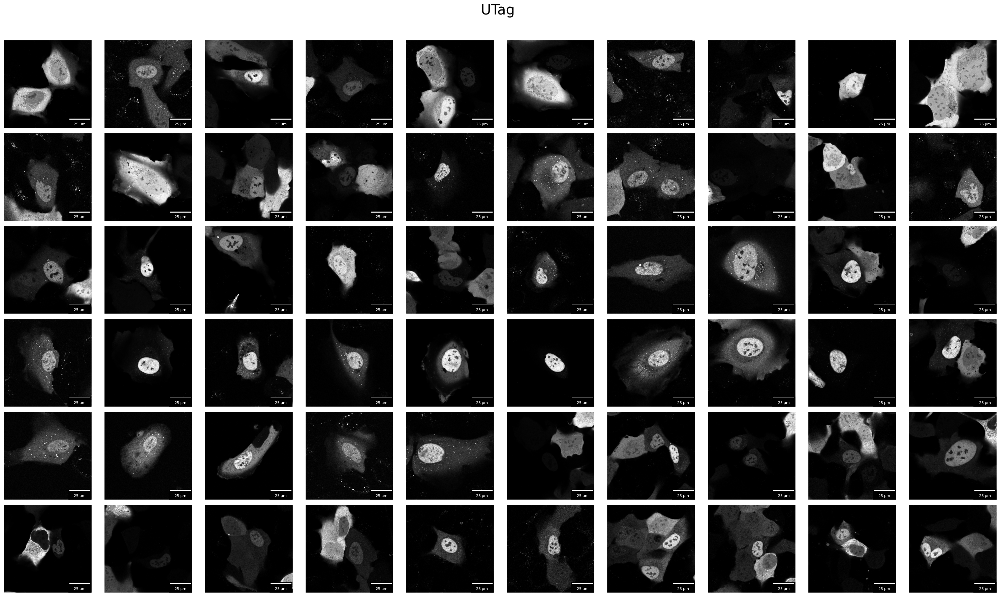

In [7]:
matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='UTag', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
flattened_images_utag = [image for sublist in list_mean_images_all_files for image in sublist]
plot_images(flattened_images_utag, list_image_names_per_file=None, tag=tag,maximum_images_to_plot=maximum_images_to_plot,microns_per_pixel =list_pixels_size[0],folder_path=folder_path)
#plot_images_line( flattened_images_utag, microns_per_pixel=list_pixels_size[0], list_selected_indexes=[21,26,32,35,38,54], save_tif_dir=save_tiff_dir_utag,overwrite=True )  

Included 04242025 24hr Tfx pNZ208_pNZ377.lif: pixel size 0.206
Included 04102025 48hr Tfx PNZ208_pNZ377.lif: pixel size 0.203
Included 04182025 48hr Tfx pNZ208_pNZ377 #2.lif: pixel size 0.206
Included 04182025 48hr Tfx pNZ208_pNZ377.lif: pixel size 0.206
Included 04252025 48hr Tfx pNZ208_pNZ377.lif: pixel size 0.206
Displaying 60 out of total images (limited by maximum_images_to_plot=60)
Saved figure as /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/final/UTag($\Delta$Cys).png


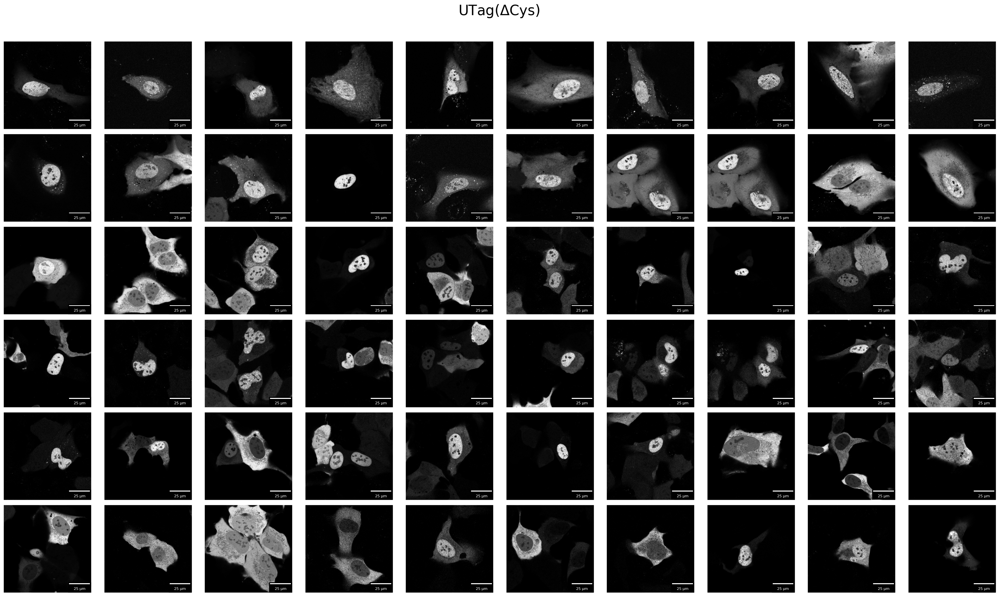

In [8]:
matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='UTag_CF', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
flattened_images_utag_cf = [image for sublist in list_mean_images_all_files for image in sublist]
plot_images(flattened_images_utag_cf, list_image_names_per_file=None, tag=tag,maximum_images_to_plot=maximum_images_to_plot,microns_per_pixel =list_pixels_size[0],folder_path=folder_path)
#plot_images_line( flattened_images_utag_cf, microns_per_pixel=list_pixels_size[0], list_selected_indexes=[13,23,27,30,35,45 ], save_tif_dir=save_tiff_dir_utag_cf,overwrite=True )  

Included 04092025 24hr Tfx pNZ266_pNZ317.lif: pixel size 0.203
Included 04172025 24hr Tfx pNZ266_pNZ317.lif: pixel size 0.206
Displaying 51 out of total images (limited by maximum_images_to_plot=60)
Saved figure as /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/final/SunTag.png


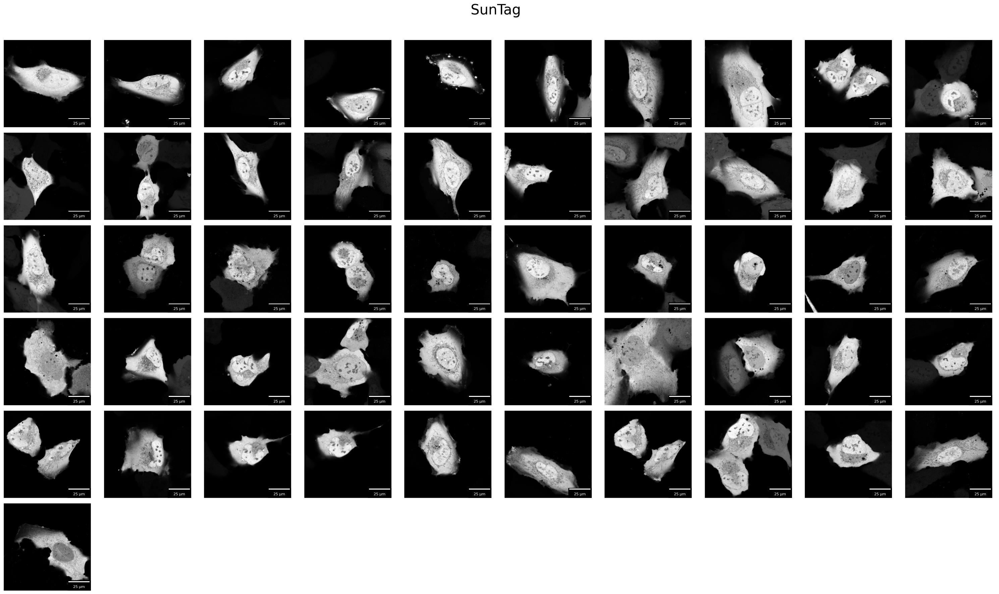

In [9]:
matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='SunTag', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
flattened_images_suntag = [image for sublist in list_mean_images_all_files for image in sublist]
plot_images(flattened_images_suntag, list_image_names_per_file=None, tag=tag,maximum_images_to_plot=maximum_images_to_plot,microns_per_pixel =list_pixels_size[0],folder_path=folder_path)
#plot_images_line( flattened_images_suntag, microns_per_pixel=list_pixels_size[0], list_selected_indexes=[0,1,2,10,12,20], save_tif_dir=save_tiff_dir_suntag,overwrite=True )  

Included 04092025 24hr Tfx pNZ267_pJY016.lif: pixel size 0.203
Included 04172025 24hr Tfx pNZ267_pJY016.lif: pixel size 0.206
Displaying 60 out of total images (limited by maximum_images_to_plot=60)
Saved figure as /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/final/Alfatag.png


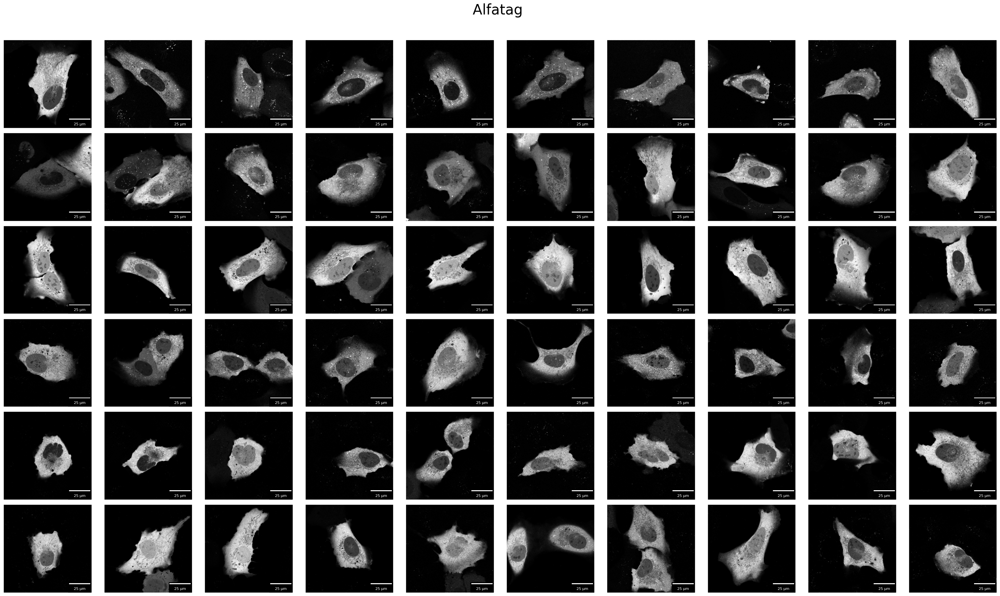

In [10]:
matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='Alfatag', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
flattened_images_alfatag = [image for sublist in list_mean_images_all_files for image in sublist]
plot_images(flattened_images_alfatag, list_image_names_per_file=None, tag=tag,maximum_images_to_plot=maximum_images_to_plot,microns_per_pixel =list_pixels_size[0],folder_path=folder_path)
#plot_images_line( flattened_images_alfatag, microns_per_pixel=list_pixels_size[0], list_selected_indexes=[0,3,4,5,26,27], save_tif_dir=save_tiff_dir_alfatag,overwrite=True )  

In [11]:
def interactive_image_cropper(list_images, crop_size=200, list_image_names=None):
    """
    Interactive image cropper that allows users to click on images to extract regions of interest.
    Users can click multiple times on the same image to find the best location, but only the last click is saved.
    
    Parameters:
    -----------
    list_images : list
        List of 2D numpy arrays (images)
    crop_size : int, optional
        Size of the cropped region (crop_size x crop_size pixels). Default is 200.
    list_image_names : list, optional
        List of image names corresponding to the images
        
    Returns:
    --------
    dict
        Dictionary containing:
        - 'cropped_images': list of cropped image arrays
        - 'click_coordinates': list of (x, y) coordinates where user clicked
        - 'image_indices': list of original image indices
        - 'image_names': list of image names (if provided)
    """
    if len(list_images) == 0:
        print("No images provided.")
        return None
    
    results = {
        'cropped_images': [],
        'click_coordinates': [],
        'image_indices': [],
        'image_names': []
    }
    
    current_idx = 0
    half_crop = crop_size // 2
    current_crop_data = None  # Store current crop data for this image
    
    def on_click(event):
        nonlocal current_idx, results, current_crop_data
        
        if event.inaxes != ax_image:
            return
        
        if event.xdata is None or event.ydata is None:
            return
        
        x, y = int(event.xdata), int(event.ydata)
        
        current_image = list_images[current_idx]
        h, w = current_image.shape
        
        x_min = max(0, x - half_crop)
        x_max = min(w, x + half_crop)
        y_min = max(0, y - half_crop)
        y_max = min(h, y + half_crop)
        
        cropped = current_image[y_min:y_max, x_min:x_max]
        
        # Pad if necessary to maintain exact crop_size
        if cropped.shape[0] < crop_size or cropped.shape[1] < crop_size:
            pad_h = max(0, crop_size - cropped.shape[0])
            pad_w = max(0, crop_size - cropped.shape[1])
            pad_top = pad_h // 2
            pad_bottom = pad_h - pad_top
            pad_left = pad_w // 2
            pad_right = pad_w - pad_left
            
            cropped = np.pad(cropped, 
                           ((pad_top, pad_bottom), (pad_left, pad_right)), 
                           mode='constant', constant_values=0)
        
        # A new click replaces the previous crop for this image.
        if list_image_names:
            image_name = list_image_names[current_idx]
        else:
            image_name = f"Image_{current_idx}"
            
        current_crop_data = {
            'cropped_image': cropped,
            'click_coordinate': (x, y),
            'image_index': current_idx,
            'image_name': image_name
        }
        
        ax_crop.clear()
        ax_crop.imshow(cropped, cmap='gray', 
                      vmin=np.percentile(cropped, 1), 
                      vmax=np.percentile(cropped, 99.9))
        ax_crop.set_title(f'Cropped Region {crop_size}x{crop_size}\nClick: ({x}, {y})', fontsize=10)
        ax_crop.set_xticks([])
        ax_crop.set_yticks([])
        
        update_main_image_with_crop(x, y, x_min, y_min, x_max, y_max)
        
        print(f"Selected crop at ({x}, {y}) from image {current_idx + 1}. Navigate to save this crop.")
    
    def update_main_image_with_crop(x, y, x_min, y_min, x_max, y_max):
        """Update main image with crop indicators"""
        ax_image.clear()
        display_image()
        
        ax_image.axhline(y=y, color='red', linestyle='--', alpha=0.7, linewidth=1)
        ax_image.axvline(x=x, color='red', linestyle='--', alpha=0.7, linewidth=1)
        ax_image.plot(x, y, 'r+', markersize=12, markeredgewidth=2)
        
        rect = Rectangle((x_min, y_min), x_max-x_min, y_max-y_min, 
                        linewidth=2, edgecolor='red', facecolor='none', alpha=0.7)
        ax_image.add_patch(rect)
        
        fig.canvas.draw_idle()
    
    def display_image():
        """Display the current image"""
        current_image = list_images[current_idx]
        ax_image.imshow(current_image, cmap='gray', 
                       vmin=np.percentile(current_image, 1), 
                       vmax=np.percentile(current_image, 99.9))
        
        has_saved_crop = current_idx in [data['image_index'] for data in 
                                        [{'image_index': idx} for idx in results['image_indices']]]
        crop_status = " (SAVED)" if has_saved_crop else ""
        
        title = f"Image {current_idx + 1}/{len(list_images)}{crop_status}"
        if list_image_names and current_idx < len(list_image_names):
            title += f"\n{list_image_names[current_idx]}"
        title += f"\nClick to crop {crop_size}x{crop_size} region"
        
        ax_image.set_title(title, fontsize=10)
        ax_image.set_xticks([])
        ax_image.set_yticks([])
    
    def save_current_crop():
        """Save the current crop data to results"""
        nonlocal current_crop_data, results
        
        if current_crop_data is None:
            print(f"No crop selected for image {current_idx + 1}")
            return
        
        # Remove any existing crop from this image
        img_idx = current_crop_data['image_index']
        if img_idx in results['image_indices']:
            idx_to_remove = results['image_indices'].index(img_idx)
            results['cropped_images'].pop(idx_to_remove)
            results['click_coordinates'].pop(idx_to_remove)
            results['image_indices'].pop(idx_to_remove)
            results['image_names'].pop(idx_to_remove)
        
        results['cropped_images'].append(current_crop_data['cropped_image'])
        results['click_coordinates'].append(current_crop_data['click_coordinate'])
        results['image_indices'].append(current_crop_data['image_index'])
        results['image_names'].append(current_crop_data['image_name'])
        
        coord = current_crop_data['click_coordinate']
        print(f"Saved crop from image {img_idx + 1} at coordinates ({coord[0]}, {coord[1]})")
        print(f"Total saved crops: {len(results['cropped_images'])}")
        
        current_crop_data = None
    
    def next_image():
        """Navigate to next image"""
        nonlocal current_idx, current_crop_data
        
        # Save current crop if exists
        if current_crop_data is not None:
            save_current_crop()
        
        if current_idx < len(list_images) - 1:
            current_idx += 1
            current_crop_data = None  # Reset for new image
            ax_image.clear()
            ax_crop.clear()
            ax_crop.set_title('Cropped Region\n(Click on image to crop)', fontsize=10)
            ax_crop.set_xticks([])
            ax_crop.set_yticks([])
            display_image()
            fig.canvas.draw_idle()
            print(f"Moved to image {current_idx + 1}")
        else:
            print("Already at last image")
    
    def prev_image():
        """Navigate to previous image"""
        nonlocal current_idx, current_crop_data
        
        # Save current crop if exists
        if current_crop_data is not None:
            save_current_crop()
        
        if current_idx > 0:
            current_idx -= 1
            current_crop_data = None  # Reset for new image
            ax_image.clear()
            ax_crop.clear()
            ax_crop.set_title('Cropped Region\n(Click on image to crop)', fontsize=10)
            ax_crop.set_xticks([])
            ax_crop.set_yticks([])
            display_image()
            fig.canvas.draw_idle()
            print(f"Moved to image {current_idx + 1}")
        else:
            print("Already at first image")
    
    def finish_cropping():
        """Finish cropping and close the interface"""
        nonlocal current_crop_data
        
        # Save current crop if exists
        if current_crop_data is not None:
            save_current_crop()
        
        plt.close(fig)
        print(f"\nCropping finished! Extracted {len(results['cropped_images'])} regions.")
        if len(results['cropped_images']) > 0:
            print("Results stored in returned dictionary:")
            print(f"- {len(results['cropped_images'])} cropped images of size {crop_size}x{crop_size}")
            print(f"- Click coordinates: {results['click_coordinates']}")
            print(f"- From images: {results['image_indices']}")
        else:
            print("No regions were cropped.")
    
    def on_key_press(event):
        """Handle keyboard navigation"""
        if event.key == 'right' or event.key == 'n':
            next_image()
        elif event.key == 'left' or event.key == 'p':
            prev_image()
        elif event.key == 'q' or event.key == 'escape':
            finish_cropping()
        elif event.key == 's':
            # Skip current image
            next_image()
        elif event.key == 'enter' or event.key == ' ':
            # Manually save current crop
            if current_crop_data is not None:
                save_current_crop()
                display_image()  # Update title to show SAVED status
        elif event.key == 'h':
            print("\nKeyboard Controls:")
            print("- Right arrow or 'n': Next image (auto-saves current crop)")
            print("- Left arrow or 'p': Previous image (auto-saves current crop)")
            print("- Enter or Space: Save current crop manually")
            print("- 's': Skip current image")
            print("- 'q' or Escape: Finish and close")
            print("- 'h': Show this help")
            print("- Click on image: Select crop region (can click multiple times)")
    
    fig, (ax_image, ax_crop) = plt.subplots(1, 2, figsize=(12, 5))
    
    display_image()
    
    ax_crop.set_title('Cropped Region\n(Click on image to crop)', fontsize=10)
    ax_crop.set_xticks([])
    ax_crop.set_yticks([])
    
    fig.canvas.mpl_connect('button_press_event', on_click)
    fig.canvas.mpl_connect('key_press_event', on_key_press)
    
    # Set focus to enable keyboard events
    fig.canvas.manager.set_window_title('Interactive Image Cropper - Multiple Clicks Allowed')
    
    print("Interactive Image Cropper Controls:")
    print("- Click on image to select crop region (multiple clicks allowed)")
    print("- Right arrow or 'n': Next image (auto-saves current crop)")
    print("- Left arrow or 'p': Previous image (auto-saves current crop)")
    print("- Enter or Space: Save current crop manually")
    print("- 's': Skip current image")
    print("- 'q' or Escape: Finish and close")
    print("- 'h': Show help")
    print("\nNote: You can click multiple times on same image to find best location!")
    print("Crop is saved when you navigate away or press Enter/Space.")
    
    plt.tight_layout()
    plt.show()
    
    return results


In [13]:
def plot_cropped_results(results, max_per_row=5, microns_per_pixel=None, save_dir=None, save_formats=['png'], filename_prefix="cropped_", show_scalebar=True, save_raw_tif=True):
    """
    Plot the results from interactive_image_cropper with scalebar and individual saving options.
    
    Parameters:
    -----------
    results : dict
        Results dictionary from interactive_image_cropper
    max_per_row : int
        Maximum number of images per row
    microns_per_pixel : float, optional
        Pixel size in micrometers for scalebar display
    save_dir : str or Path, optional
        Directory to save individual images. If None, no saving occurs.
    save_formats : list, optional
        List of formats to save ['png', 'svg', 'pdf', 'tiff']. Default is ['png'].
    filename_prefix : str, optional
        Prefix for saved filenames. Default is "cropped_".
    show_scalebar : bool, optional
        Whether to show scalebar on images. Default is True.
    save_raw_tif : bool, optional
        Whether to save raw TIFF files (ImageJ compatible). Default is True.
    """
    if not results or len(results['cropped_images']) == 0:
        print("No cropped images to display.")
        return
    
    cropped_images = results['cropped_images']
    n_images = len(cropped_images)
    
    n_cols = min(max_per_row, n_images)
    n_rows = int(np.ceil(n_images / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    if n_images == 1:
        axes = [axes]
    elif n_rows == 1:
        axes = axes.reshape(1, -1)
    axes = axes.flatten()
    
    # Font properties for scalebar
    font_props = {'size': 8}
    
    for i, (img, ax) in enumerate(zip(cropped_images, axes)):
        ax.imshow(img, cmap='gray', 
                 vmin=np.percentile(img, 1), 
                 vmax=np.percentile(img, 99.9))
        
        # Create title with info
        coord = results['click_coordinates'][i]
        img_idx = results['image_indices'][i]
        img_name = results['image_names'][i]
        
        title = f"{img_name}\nClick: ({coord[0]}, {coord[1]})\nFrom Image {img_idx}"
        ax.set_title(title, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
        
        # Add scalebar if microns_per_pixel is provided
        if microns_per_pixel is not None and show_scalebar:
            try:
                from matplotlib_scalebar.scalebar import ScaleBar
                scalebar = ScaleBar(dx=microns_per_pixel, units='um', length_fraction=0.25,
                                    location='lower right', box_color='k', color='w',
                                    font_properties=font_props, label='')
                ax.add_artist(scalebar)
            except ImportError:
                print("Warning: matplotlib-scalebar not available. Install with: pip install matplotlib-scalebar")
    
    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    
    plt.suptitle(f'Cropped Regions ({n_images} total)', fontsize=16)
    plt.tight_layout()
    
    # Save the combined figure if save_dir is provided
    if save_dir is not None:
        save_path = Path(save_dir)
        save_path.mkdir(parents=True, exist_ok=True)
        
        for fmt in save_formats:
            combined_file = save_path / f"{filename_prefix}combined.{fmt}"
            if fmt == 'svg':
                plt.savefig(combined_file, format='svg', dpi=300, bbox_inches='tight')
            elif fmt == 'pdf':
                plt.savefig(combined_file, format='pdf', dpi=300, bbox_inches='tight')
            elif fmt == 'tiff':
                plt.savefig(combined_file, format='tiff', dpi=300, bbox_inches='tight')
            else:  # png and others
                plt.savefig(combined_file, format=fmt, dpi=300, bbox_inches='tight')
        
        print(f"Saved combined figure to: {save_path}")
    
    plt.show()
    
    # Save individual images if save_dir is provided
    if save_dir is not None:
        save_individual_cropped_images(results, save_dir, save_formats, filename_prefix, microns_per_pixel, show_scalebar, save_raw_tif)

In [18]:
def save_individual_cropped_images(results, save_dir, save_formats=['png'], filename_prefix="cropped_", microns_per_pixel=None, show_scalebar=True, save_raw_tif=True):
    """
    Save individual cropped images with scalebars and optionally raw TIFF files.
    
    Parameters:
    -----------
    results : dict
        Results dictionary from interactive_image_cropper
    save_dir : str or Path
        Directory to save individual images
    save_formats : list, optional
        List of formats to save ['png', 'svg', 'pdf', 'tiff']. Default is ['png'].
    filename_prefix : str, optional
        Prefix for saved filenames. Default is "cropped_".
    microns_per_pixel : float, optional
        Pixel size in micrometers for scalebar display
    show_scalebar : bool, optional
        Whether to show scalebar on images. Default is True.
    save_raw_tif : bool, optional
        Whether to save raw TIFF files (ImageJ compatible) in addition to plot formats. Default is True.
    """
    if not results or len(results['cropped_images']) == 0:
        print("No cropped images to save.")
        return
    
    save_path = Path(save_dir)
    save_path.mkdir(parents=True, exist_ok=True)
    
    # Font properties for scalebar
    font_props = {'size': 0}
    
    saved_files = []
    
    # Helper functions from plot_images_line
    def _sanitize_filename(s):
        base = str(s).strip().replace(' ', '_')
        return re.sub(r'[^A-Za-z0-9_\-]+', '', base) or "image"

    def _compute_resolution_tags(pixel_um):
        """
        TIFF stores XResolution/YResolution as 'pixels per unit'.
        We use unit = CENTIMETER: px/cm = 10000 / (µm/pixel).
        """
        if pixel_um is None:
            return (None, None)
        pixel_um = float(pixel_um)
        if pixel_um <= 0:
            raise ValueError("microns_per_pixel must be > 0.")
        px_per_cm = 10000.0 / pixel_um
        return ((px_per_cm, px_per_cm), "CENTIMETER")

    def _to_imagej_compatible_dtype(arr):
        """
        Convert array to an ImageJ-compatible dtype without changing dynamic range
        (no normalization). Returns a contiguous array with dtype in {uint8, uint16, int16, float32}.
        """
        a = np.asarray(arr)
        # Allowed ImageJ dtypes per tifffile: 'B' (uint8), 'H' (uint16), 'h' (int16), 'f' (float32)
        if a.dtype == np.uint8 or a.dtype == np.uint16 or a.dtype == np.int16 or a.dtype == np.float32:
            return np.ascontiguousarray(a)
        if a.dtype == np.bool_:
            # map False/True -> 0/255 (uint8)
            return np.ascontiguousarray(a.astype(np.uint8) * 255)
        if np.issubdtype(a.dtype, np.floating):
            # float64/float16 -> float32 (no scaling)
            return np.ascontiguousarray(a.astype(np.float32))
        # other integer types (int8, int32, int64, uint32, uint64) -> float32 to avoid overflow
        return np.ascontiguousarray(a.astype(np.float32))
    
    for i, img in enumerate(results['cropped_images']):
        # Generate filename components
        coord = results['click_coordinates'][i]
        img_idx = results['image_indices'][i]
        img_name = results['image_names'][i]
        
        # Clean filename
        clean_name = _sanitize_filename(str(img_name))
        base_filename = f"{_sanitize_filename(filename_prefix)}{i+1:03d}_{clean_name}_img{img_idx}_coord{coord[0]}_{coord[1]}"
        
        # Save raw TIFF file (ImageJ compatible) if requested
        if save_raw_tif:
            raw_tif_path = save_path / f"{base_filename}_raw.tif"
            
            # Ensure ImageJ-compatible dtype and contiguous memory
            img_ij = _to_imagej_compatible_dtype(img)
            
            # Compute resolution tags
            resolution, resolutionunit = _compute_resolution_tags(microns_per_pixel)
            
            # ImageJ-only metadata (no OME fields)
            base_metadata = {'axes': 'YX'}
            if microns_per_pixel is not None:
                base_metadata['unit'] = 'um'
            
            # Write raw TIFF file
            imwrite_kwargs = {
                "imagej": True,
                "ome": False,  # do NOT mix OME with ImageJ
                "metadata": base_metadata
            }
            if resolution is not None:
                imwrite_kwargs.update({
                    "resolution": resolution,
                    "resolutionunit": resolutionunit
                })
            
            tifffile.imwrite(str(raw_tif_path), img_ij, **imwrite_kwargs)
            saved_files.append(str(raw_tif_path))
        
        # Save plot formats (with scalebar if requested)
        if save_formats:
            # Create individual figure for each image
            fig, ax = plt.subplots(1, 1, figsize=(6, 6))
            
            # Display image
            ax.imshow(img, cmap='gray', 
                     vmin=np.percentile(img, 1), 
                     vmax=np.percentile(img, 99.9))
            
            # Remove ticks and labels for clean image
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_frame_on(False)
            
            # Add scalebar if microns_per_pixel is provided
            if microns_per_pixel is not None and show_scalebar:
                try:
                    from matplotlib_scalebar.scalebar import ScaleBar
                    scalebar = ScaleBar(dx=microns_per_pixel, units='um', length_fraction=0.2,
                                        location='lower right', box_color='k', color='w',
                                        font_properties=font_props, label='')
                    ax.add_artist(scalebar)
                except ImportError:
                    print("Warning: matplotlib-scalebar not available. Install with: pip install matplotlib-scalebar")
            
            # Save in specified formats
            for fmt in save_formats:
                file_path = save_path / f"{base_filename}.{fmt}"
                
                if fmt == 'svg':
                    plt.savefig(file_path, format='svg', dpi=300, bbox_inches='tight', pad_inches=0)
                elif fmt == 'pdf':
                    plt.savefig(file_path, format='pdf', dpi=300, bbox_inches='tight', pad_inches=0)
                elif fmt == 'tiff':
                    plt.savefig(file_path, format='tiff', dpi=300, bbox_inches='tight', pad_inches=0)
                else:  # png and others
                    plt.savefig(file_path, format=fmt, dpi=300, bbox_inches='tight', pad_inches=0)
                
                saved_files.append(str(file_path))
            
            plt.close(fig)  # Close individual figure to save memory
    
    print(f"Saved {len(saved_files)} files to: {save_path}")
    if save_raw_tif and microns_per_pixel is not None:
        print(f"Raw TIFF files include embedded calibration: {microns_per_pixel} µm/pixel (XY)")
    if save_formats and microns_per_pixel is not None and show_scalebar:
        print(f"Plot images include scalebar with calibration: {microns_per_pixel} µm/pixel")
    
    return saved_files

In [15]:
raise NotImplementedError("Plotting function not implemented yet.")

NotImplementedError: Plotting function not implemented yet.

In [17]:
%matplotlib widget

In [21]:
crop_size = 300

Interactive Image Cropper Controls:
- Click on image to select crop region (multiple clicks allowed)
- Right arrow or 'n': Next image (auto-saves current crop)
- Left arrow or 'p': Previous image (auto-saves current crop)
- Enter or Space: Save current crop manually
- 's': Skip current image
- 'q' or Escape: Finish and close
- 'h': Show help

Note: You can click multiple times on same image to find best location!
Crop is saved when you navigate away or press Enter/Space.


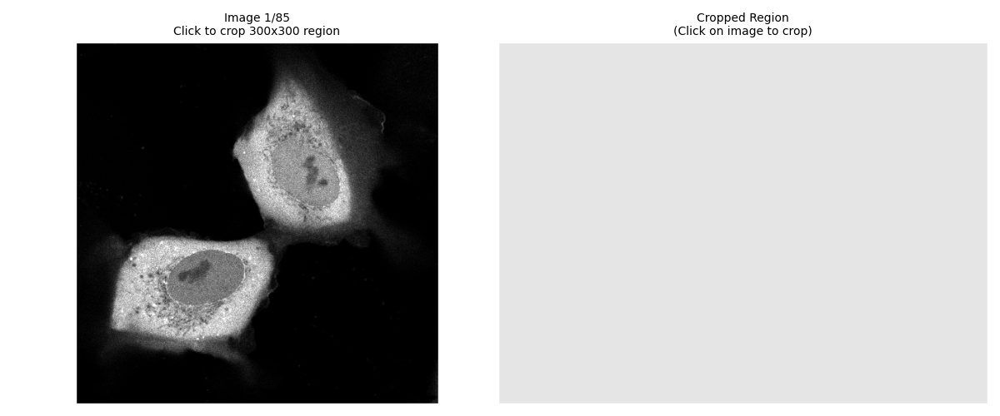

In [23]:
results_utag = interactive_image_cropper(flattened_images_utag, crop_size=crop_size)

In [24]:

save_individual_cropped_images(results_utag, save_dir=save_tiff_dir_utag, save_formats=['png'], filename_prefix="zoom_", microns_per_pixel=list_pixels_size[0] )


Saved 64 files to: /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag
Raw TIFF files include embedded calibration: 0.20338786692759298 µm/pixel (XY)
Plot images include scalebar with calibration: 0.20338786692759298 µm/pixel


['/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag/zoom_001_Image_2_img2_coord244_233_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag/zoom_001_Image_2_img2_coord244_233.png',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag/zoom_002_Image_14_img14_coord212_236_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag/zoom_002_Image_14_img14_coord212_236.png',
 '/Users/nzlab-la/Li

Interactive Image Cropper Controls:
- Click on image to select crop region (multiple clicks allowed)
- Right arrow or 'n': Next image (auto-saves current crop)
- Left arrow or 'p': Previous image (auto-saves current crop)
- Enter or Space: Save current crop manually
- 's': Skip current image
- 'q' or Escape: Finish and close
- 'h': Show help

Note: You can click multiple times on same image to find best location!
Crop is saved when you navigate away or press Enter/Space.


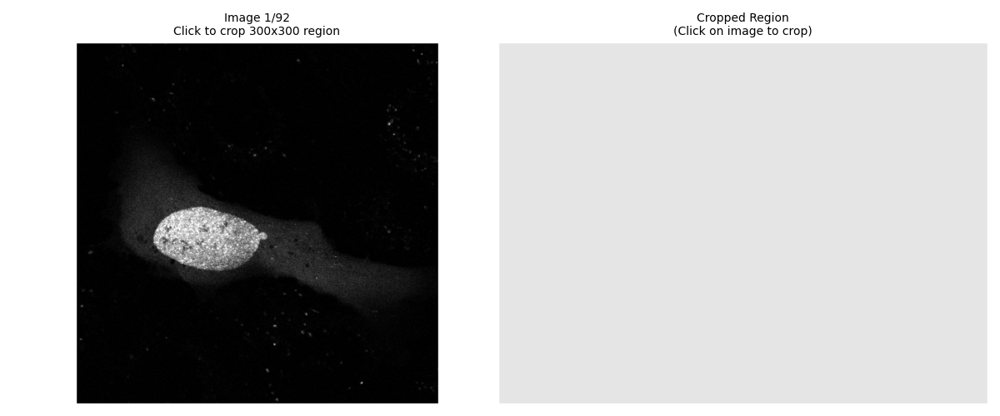

In [25]:
results_utag_cf = interactive_image_cropper(flattened_images_utag_cf, crop_size=crop_size)

In [26]:
save_individual_cropped_images(results_utag_cf, save_dir=save_tiff_dir_utag_cf, save_formats=['png'], filename_prefix="zoom_", microns_per_pixel=list_pixels_size[0] )


Saved 58 files to: /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag_CF
Raw TIFF files include embedded calibration: 0.20338786692759298 µm/pixel (XY)
Plot images include scalebar with calibration: 0.20338786692759298 µm/pixel


['/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag_CF/zoom_001_Image_0_img0_coord172_285_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag_CF/zoom_001_Image_0_img0_coord172_285.png',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag_CF/zoom_002_Image_3_img3_coord221_301_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/UTag_CF/zoom_002_Image_3_img3_coord221_301.png',
 '/Users/nzl

Interactive Image Cropper Controls:
- Click on image to select crop region (multiple clicks allowed)
- Right arrow or 'n': Next image (auto-saves current crop)
- Left arrow or 'p': Previous image (auto-saves current crop)
- Enter or Space: Save current crop manually
- 's': Skip current image
- 'q' or Escape: Finish and close
- 'h': Show help

Note: You can click multiple times on same image to find best location!
Crop is saved when you navigate away or press Enter/Space.


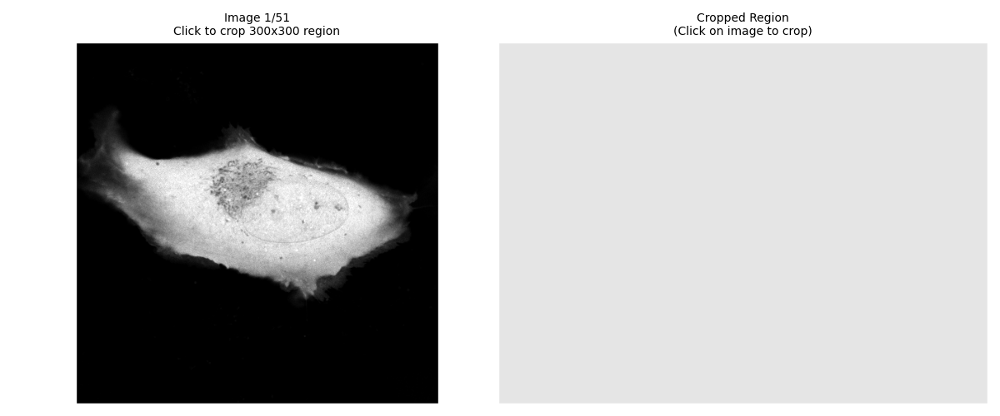

In [29]:
results_suntag = interactive_image_cropper(flattened_images_suntag, crop_size=crop_size)

In [30]:
save_individual_cropped_images(results_suntag, save_dir=save_tiff_dir_suntag, save_formats=['png'], filename_prefix="zoom_", microns_per_pixel=list_pixels_size[0] )

Saved 40 files to: /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/SunTag
Raw TIFF files include embedded calibration: 0.20338786692759298 µm/pixel (XY)
Plot images include scalebar with calibration: 0.20338786692759298 µm/pixel


['/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/SunTag/zoom_001_Image_0_img0_coord264_253_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/SunTag/zoom_001_Image_0_img0_coord264_253.png',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/SunTag/zoom_002_Image_1_img1_coord305_276_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/SunTag/zoom_002_Image_1_img1_coord305_276.png',
 '/Users/nzlab-l

Interactive Image Cropper Controls:
- Click on image to select crop region (multiple clicks allowed)
- Right arrow or 'n': Next image (auto-saves current crop)
- Left arrow or 'p': Previous image (auto-saves current crop)
- Enter or Space: Save current crop manually
- 's': Skip current image
- 'q' or Escape: Finish and close
- 'h': Show help

Note: You can click multiple times on same image to find best location!
Crop is saved when you navigate away or press Enter/Space.


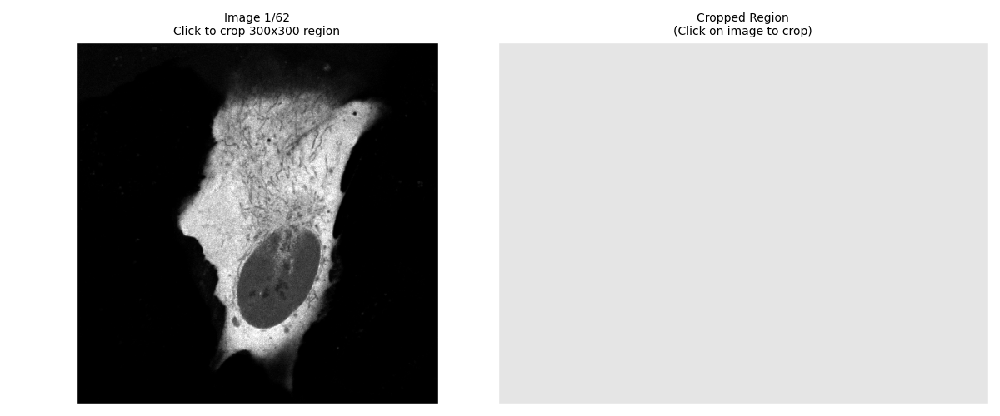

In [31]:
results_alfatag = interactive_image_cropper(flattened_images_alfatag, crop_size=crop_size)

In [32]:
save_individual_cropped_images(results_alfatag, save_dir=save_tiff_dir_alfatag, save_formats=['png'], filename_prefix="zoom_", microns_per_pixel=list_pixels_size[0] )

Saved 48 files to: /Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/Alfatag
Raw TIFF files include embedded calibration: 0.20338786692759298 µm/pixel (XY)
Plot images include scalebar with calibration: 0.20338786692759298 µm/pixel


['/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/Alfatag/zoom_001_Image_0_img0_coord277_312_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/Alfatag/zoom_001_Image_0_img0_coord277_312.png',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/Alfatag/zoom_002_Image_3_img3_coord253_280_raw.tif',
 '/Users/nzlab-la/Library/CloudStorage/OneDrive-TheUniversityofColoradoDenver/General - Zhao (NZ) Lab/Zhao lab shared folder/Our papers/Anti-Utag-frankenbody paper/Fig. S Translocation/tif_images/Alfatag/zoom_002_Image_3_img3_coord253_280.png',
 '/Users/nzl

In [ ]:
raise SystemExit 

# Plotting each data set independently
___


In [ ]:

matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='UTag', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
for i, matching_file_name in enumerate(matching_file_names):
    list_images_per_file = list_mean_images_all_files[i]
    list_image_names_per_file = list_names_all_files[i]
    plot_images(list_images_per_file,list_image_names_per_file, matching_file_name, tag)

In [ ]:
matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='UTag_CF', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
for i, matching_file_name in enumerate(matching_file_names):
    list_images_per_file = list_mean_images_all_files[i]
    list_image_names_per_file = list_names_all_files[i]
    plot_images(list_images_per_file,list_image_names_per_file, matching_file_name, tag)


In [ ]:
matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='SunTag', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
for i, matching_file_name in enumerate(matching_file_names):
    list_images_per_file = list_mean_images_all_files[i]
    list_image_names_per_file = list_names_all_files[i]
    plot_images(list_images_per_file,list_image_names_per_file, matching_file_name, tag)

In [ ]:
matching_file_names, list_mean_images_all_files, list_names_all_files, list_pixels_size, tag, time = get_mean_images(tag='Alfatag', time=None,folder_path=folder_path,pixel_filter=pixel_filter)
for i, matching_file_name in enumerate(matching_file_names):
    list_images_per_file = list_mean_images_all_files[i]
    list_image_names_per_file = list_names_all_files[i]
    plot_images(list_images_per_file,list_image_names_per_file, matching_file_name, tag)